In [1]:
import numpy as np
import fastplotlib as fpl
import tifffile

import cv2
import logging
import numpy as np
import scipy
from scipy.ndimage import  correlate
from sklearn.decomposition import NMF
import sys

from matplotlib import pyplot as plt
%matplotlib inline

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon Graphics (RADV REMBRANDT),IntegratedGPU,Vulkan,Mesa 22.3.6
✅ (default),NVIDIA T1200 Laptop GPU,DiscreteGPU,Vulkan,535.129.03
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [6]:
fpl.select_adapter(fpl.enumerate_adapters()[1])

In [7]:
def imblur(Y, sig=5, siz=11, nDimBlur=None, kernel=None, opencv=True):
    """
    Spatial filtering with a Gaussian or user defined kernel

    The parameters are specified in GreedyROI

    Args:
        Y: np.ndarray
            d1 x d2 [x d3] x T movie, raw data.

        sig: [optional] list,tuple
            half size of neurons

        siz: [optional] list,tuple
            size of filter kernel (default 2*sig + 1).

        nDimBlur: [optional]
            if you want to specify the number of dimension

        kernel: [optional]
            if you want to specify a kernel

        opencv: [optional]
            if you want to process to the blur using OpenCV method

    Returns:
        the blurred image
    """
    # TODO: document (jerem)
    if kernel is None:
        if nDimBlur is None:
            nDimBlur = Y.ndim - 1
        else:
            nDimBlur = np.min((Y.ndim, nDimBlur))

        if np.isscalar(sig):
            sig = sig * np.ones(nDimBlur)

        if np.isscalar(siz):
            siz = siz * np.ones(nDimBlur)

        X = Y.copy()
        if opencv and nDimBlur == 2:
            if X.ndim > 2:
                # if we are on a video we repeat for each frame
                for frame in range(X.shape[-1]):
                    if sys.version_info >= (3, 0):
                        X[:, :, frame] = cv2.GaussianBlur(X[:, :, frame], tuple(
                            siz), sig[0], None, sig[1], cv2.BORDER_CONSTANT)
                    else:
                        X[:, :, frame] = cv2.GaussianBlur(X[:, :, frame], tuple(siz), sig[
                                                          0], sig[1], cv2.BORDER_CONSTANT, 0)

            else:
                if sys.version_info >= (3, 0):
                    X = cv2.GaussianBlur(
                        X, tuple(siz), sig[0], None, sig[1], cv2.BORDER_CONSTANT)
                else:
                    X = cv2.GaussianBlur(
                        X, tuple(siz), sig[0], sig[1], cv2.BORDER_CONSTANT, 0)
        else:
            for i in range(nDimBlur):
                h = np.exp(-np.arange(-np.floor(siz[i] / 2),
                                       np.floor(siz[i] / 2) + 1)**2 / (2 * sig[i]**2))
                h /= np.sqrt(h.dot(h))
                shape = [1] * len(Y.shape)
                shape[i] = -1
                X = correlate(X, h.reshape(shape), mode='constant')

    else:
        X = correlate(Y, kernel[..., np.newaxis], mode='constant')
        # for t in range(np.shape(Y)[-1]):
        #    X[:,:,t] = correlate(Y[:,:,t],kernel,mode='constant', cval=0.0)

    return X


In [8]:
def finetune(Y, cin, nIter=5):
    """compute a initialized version of A and C

    Args:
        Y:  D1*d2*T*K patches

        c: array T*K
            the initial calcium traces

        nIter: int
            True indicates that time is listed in the last axis of Y (matlab format)
            and moves it in the front

    Returns:
    a: array (d1,D2) the computed A as l2(Y*C)/Y*C

    c: array(T) C as the sum of As on x*y axis
"""
    debug_ = False
    if debug_:
        import os
        f = open('_LOG_1_' + str(os.getpid()), 'w+')
        f.write('Y:' + str(np.mean(Y)) + '\n')
        f.write('cin:' + str(np.mean(cin)) + '\n')
        f.close()

    # we compute the multiplication of patches per traces ( non negatively )
    for _ in range(nIter):
        a = np.maximum(np.dot(Y, cin), 0)
        a = a / np.sqrt(np.sum(a**2) + np.finfo(np.float32).eps)  # compute the l2/a
        # c as the variation of those patches
        cin = np.sum(Y * a[..., np.newaxis], tuple(np.arange(Y.ndim - 1)))

    return a, cin


In [9]:
def greedyROI(Y, nr=30, gSig=[5, 5], gSiz=[11, 11], nIter=5, kernel=None, nb=1,
              rolling_sum=False, rolling_length=100, seed_method='auto'):
    """
    Greedy initialization of spatial and temporal components using spatial Gaussian filtering

    Args:
        Y: np.array
            3d or 4d array of fluorescence data with time appearing in the last axis.

        nr: int
            number of components to be found

        gSig: scalar or list of integers
            standard deviation of Gaussian kernel along each axis

        gSiz: scalar or list of integers
            size of spatial component

        nIter: int
            number of iterations when refining estimates

        kernel: np.ndarray
            User specified kernel to be used, if present, instead of Gaussian (default None)

        nb: int
            Number of background components

        rolling_max: boolean
            Detect new components based on a rolling sum of pixel activity (default: True)

        rolling_length: int
            Length of rolling window (default: 100)

        seed_method: str {'auto', 'manual', 'semi'}
            methods for choosing seed pixels
            'semi' detects nr components automatically and allows to add more manually
            if running as notebook 'semi' and 'manual' require a backend that does not
            inline figures, e.g. %matplotlib tk

    Returns:
        A: np.array
            2d array of size (# of pixels) x nr with the spatial components. Each column is
            ordered columnwise (matlab format, order='F')

        C: np.array
            2d array of size nr X T with the temporal components

        center: np.array
            2d array of size nr x 2 [ or 3] with the components centroids

    Author:
        Eftychios A. Pnevmatikakis and Andrea Giovannucci based on a matlab implementation by Yuanjun Gao
            Simons Foundation, 2015

    See Also:
        http://www.cell.com/neuron/pdf/S0896-6273(15)01084-3.pdf


    """
    logging.info("Greedy initialization of spatial and temporal components using spatial Gaussian filtering")
    d = np.shape(Y)
    Y[np.isnan(Y)] = 0
    med = np.median(Y, axis=-1)
    Y = Y - med[..., np.newaxis]
    gHalf = np.array(gSiz) // 2
    gSiz = 2 * gHalf + 1
    # we initialize every values to zero
    if seed_method.lower() == 'manual':
        nr = 0
    A = np.zeros((np.prod(d[0:-1]), nr), dtype=np.float32)
    C = np.zeros((nr, d[-1]), dtype=np.float32)
    center = np.zeros((nr, Y.ndim - 1), dtype='uint16')

    rho = imblur(Y, sig=gSig, siz=gSiz, nDimBlur=Y.ndim - 1, kernel=kernel)

    
    if rolling_sum:
        logging.info('Using rolling sum for initialization (RollingGreedyROI)')
        rolling_filter = np.ones(
            (rolling_length), dtype=np.float32) / rolling_length
        rho_s = scipy.signal.lfilter(rolling_filter, 1., rho**2)
        return rho_s
        v = np.amax(rho_s, axis=-1)
    else:
        logging.info('Using total sum for initialization (GreedyROI)')
        v = np.sum(rho**2, axis=-1)


    if seed_method.lower() != 'manual':
        for k in range(nr):
            # we take the highest value of the blurred total image and we define it as
            # the center of the neuron
            ind = np.argmax(v)
            ij = np.unravel_index(ind, d[0:-1])
            for c, i in enumerate(ij):
                center[k, c] = i

            # we define a squared size around it
            ijSig = [[np.maximum(ij[c] - gHalf[c], 0), np.minimum(ij[c] + gHalf[c] + 1, d[c])]
                     for c in range(len(ij))]
            # we create an array of it (fl like) and compute the trace like the pixel ij through time
            dataTemp = np.array(
                Y[tuple([slice(*a) for a in ijSig])].copy(), dtype=np.float32)
            traceTemp = np.array(np.squeeze(rho[ij]), dtype=np.float32)

            coef, score = finetune(dataTemp, traceTemp, nIter=nIter)
            C[k, :] = np.squeeze(score)
            dataSig = coef[..., np.newaxis] * \
                score.reshape([1] * (Y.ndim - 1) + [-1])
            xySig = np.meshgrid(*[np.arange(s[0], s[1])
                                  for s in ijSig], indexing='xy')
            arr = np.array([np.reshape(s, (1, np.size(s)), order='F').squeeze()
                            for s in xySig], dtype=int)
            indices = np.ravel_multi_index(arr, d[0:-1], order='F')

            A[indices, k] = np.reshape(
                coef, (1, np.size(coef)), order='C').squeeze()
            Y[tuple([slice(*a) for a in ijSig])] -= dataSig.copy()
            if k < nr - 1 or seed_method.lower() != 'auto':
                Mod = [[np.maximum(ij[c] - 2 * gHalf[c], 0),
                        np.minimum(ij[c] + 2 * gHalf[c] + 1, d[c])] for c in range(len(ij))]
                ModLen = [m[1] - m[0] for m in Mod]
                Lag = [ijSig[c] - Mod[c][0] for c in range(len(ij))]
                dataTemp = np.zeros(ModLen)
                dataTemp[tuple([slice(*a) for a in Lag])] = coef
                dataTemp = imblur(dataTemp[..., np.newaxis],
                                  sig=gSig, siz=gSiz, kernel=kernel)
                temp = dataTemp * score.reshape([1] * (Y.ndim - 1) + [-1])
                rho[tuple([slice(*a) for a in Mod])] -= temp.copy()
                if rolling_sum:
                    rho_filt = scipy.signal.lfilter(
                        rolling_filter, 1., rho[tuple([slice(*a) for a in Mod])]**2)
                    v[tuple([slice(*a) for a in Mod])] = np.amax(rho_filt, axis=-1)
                else:
                    v[tuple([slice(*a) for a in Mod])] = \
                        np.sum(rho[tuple([slice(*a) for a in Mod])]**2, axis=-1)
        center = center.tolist()
    else:
        center = []

    res = np.reshape(Y, (np.prod(d[0:-1]), d[-1]),
                     order='F') + med.flatten(order='F')[:, None]
#    model = NMF(n_components=nb, init='random', random_state=0)
    model = NMF(n_components=nb, init='nndsvdar')
    b_in = model.fit_transform(np.maximum(res, 0)).astype(np.float32)
    f_in = model.components_.astype(np.float32)

    return A, C, np.array(center, dtype='uint16'), b_in, f_in


In [10]:
movie = tifffile.imread("/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif")[:10_000:1, 128:-138:2, 138:-132:2].astype(np.float32)

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
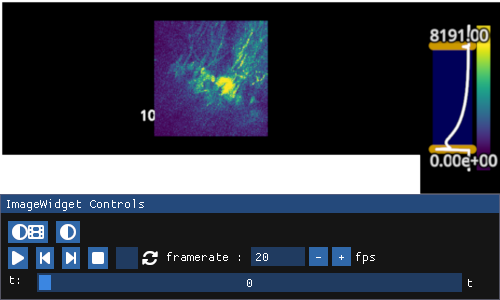

In [11]:
iw = fpl.ImageWidget(movie, cmap="viridis")
iw.show()

In [16]:
series = movie.reshape(movie.shape[0], movie.shape[1] * movie.shape[2], order="F").T

In [17]:
Y = movie.T

In [18]:
nr=30
gSig=[5, 5]
gSiz=[11, 11]
nIter=5
kernel=None
nb=1
rolling_sum=False
rolling_length=100
seed_method='auto'

In [19]:
d = np.shape(Y)
Y[np.isnan(Y)] = 0
med = np.median(Y, axis=-1)
Y = Y - med[..., np.newaxis]
gHalf = np.array(gSiz) // 2
gSiz = 2 * gHalf + 1
# we initialize every values to zero
if seed_method.lower() == 'manual':
    nr = 0
A = np.zeros((np.prod(d[0:-1]), nr), dtype=np.float32)
C = np.zeros((nr, d[-1]), dtype=np.float32)
center = np.zeros((nr, Y.ndim - 1), dtype='uint16')

rho = imblur(Y, sig=gSig, siz=gSiz, nDimBlur=Y.ndim - 1, kernel=kernel)

In [20]:
rho.shape

(121, 123, 10000)

RFBOutputContext()

JupyterWgpuCanvas()
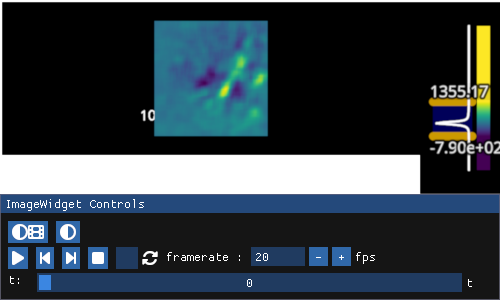

In [21]:
fpl.ImageWidget(rho.T, cmap="viridis").show()

In [22]:
v = np.sum(rho ** 2, axis=-1)

In [23]:
rolling_filter = np.ones(
    (rolling_length), dtype=np.float32) / rolling_length
rho_s = scipy.signal.lfilter(rolling_filter, 1., rho ** 2)
v2 = np.amax(rho_s, axis=-1)

In [24]:
v.min(), v.max()

(np.float32(10059949.0), np.float32(7149322000.0))

In [25]:
iw = fpl.ImageWidget(v, cmap="viridis", histogram_widget=False)
iw.show(sidecar=True)

RFBOutputContext()

In [26]:
center = np.zeros((nr, Y.ndim - 1), dtype='uint16')

In [27]:
k = 0

# we take the highest value of the blurred total image and we define it as
# the center of the neuron
ind = np.argmax(v)
ij = np.unravel_index(ind, d[:-1])
center[k] = ij

In [28]:
center

array([[58, 79],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0],
       [ 0,  0]], dtype=uint16)

In [29]:
iw.figure[0, 0].add_scatter(np.fliplr(center[None, k]), colors=(1, 0, 0, 0.7), sizes=10)

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting uint16 array to float32
  warn(f"casting {array.dtype} array to float32")


ScatterGraphic @ 0x7f2178bf48d0

In [30]:
# we define a squared size around it
ijSig = [[np.maximum(ij[c] - gHalf[c], 0), np.minimum(ij[c] + gHalf[c] + 1, d[c])]
         for c in range(len(ij))]

In [31]:
ijSig

[[np.int64(53), np.int64(64)], [np.int64(74), np.int64(85)]]

In [32]:
dataTemp = np.array(
    Y[tuple([slice(*a) for a in ijSig])].copy(), dtype=np.float32)
traceTemp = np.array(np.squeeze(rho[ij]), dtype=np.float32)

In [33]:
dataTemp.shape

(11, 11, 10000)

RFBOutputContext()

JupyterWgpuCanvas()
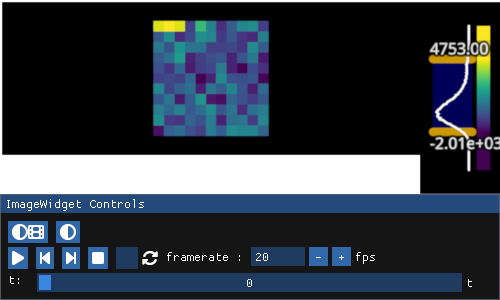

In [34]:
fpl.ImageWidget(dataTemp.T, cmap="viridis").show()

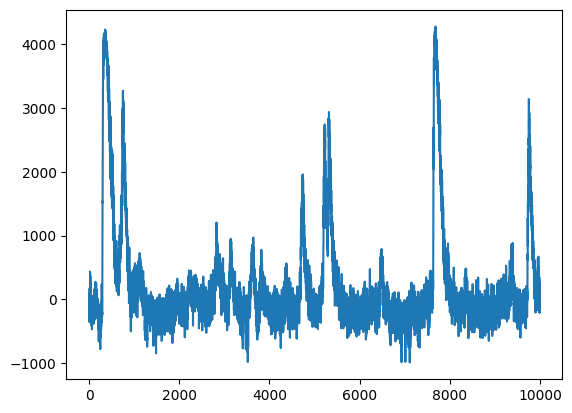

In [35]:
plt.plot(traceTemp)

In [36]:
coef, score = finetune(dataTemp, traceTemp, nIter=nIter)

In [37]:
coef.shape

(11, 11)

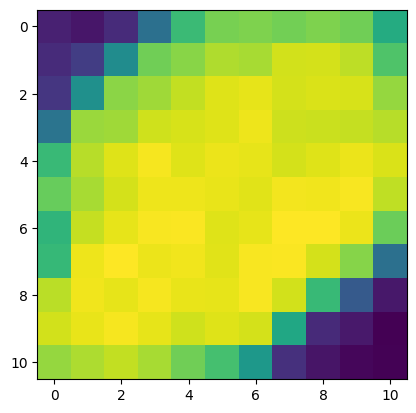

In [38]:
plt.imshow(coef)

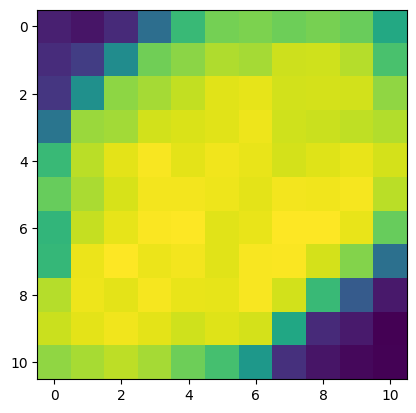

In [39]:
plt.imshow(np.dot(dataTemp, traceTemp))

In [40]:
C[k] = np.squeeze(score)

In [41]:
dataSig = coef[..., np.newaxis] * score.reshape([1] * (Y.ndim - 1) + [-1])

In [42]:
dataSig.shape

(11, 11, 10000)

RFBOutputContext()

JupyterWgpuCanvas()
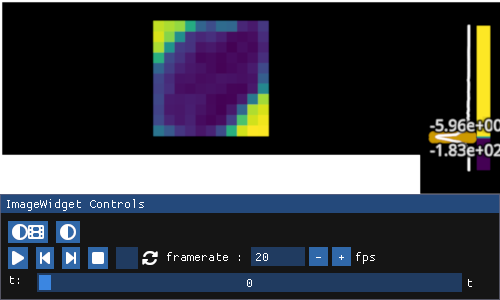

In [43]:
fpl.ImageWidget(dataSig.T, cmap="viridis").show()

In [44]:
xySig = np.meshgrid(*[np.arange(s[0], s[1]) for s in ijSig], indexing='xy')

In [45]:
xySig

(array([[53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63],
        [53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]]),
 array([[74, 74, 74, 74, 74, 74, 74, 74, 74, 74, 74],
        [75, 75, 75, 75, 75, 75, 75, 75, 75, 75, 75],
        [76, 76, 76, 76, 76, 76, 76, 76, 76, 76, 76],
        [77, 77, 77, 77, 77, 77, 77, 77, 77, 77, 77],
        [78, 78, 78, 78, 78, 78, 78, 78, 78, 78, 78],
        [79, 79, 79, 79, 79, 79, 79, 79, 79, 79, 79],
        [80, 80, 80, 80, 80, 80, 80, 80, 80, 80, 80],
        [81, 81, 81, 81, 8

In [46]:
arr = np.array([np.reshape(s, (1, np.size(s)), order='F').squeeze() for s in xySig], dtype=int)

In [47]:
arr.shape

(2, 121)

In [48]:
arr

array([[53, 53, 53, 53, 53, 53, 53, 53, 53, 53, 53, 54, 54, 54, 54, 54,
        54, 54, 54, 54, 54, 54, 55, 55, 55, 55, 55, 55, 55, 55, 55, 55,
        55, 56, 56, 56, 56, 56, 56, 56, 56, 56, 56, 56, 57, 57, 57, 57,
        57, 57, 57, 57, 57, 57, 57, 58, 58, 58, 58, 58, 58, 58, 58, 58,
        58, 58, 59, 59, 59, 59, 59, 59, 59, 59, 59, 59, 59, 60, 60, 60,
        60, 60, 60, 60, 60, 60, 60, 60, 61, 61, 61, 61, 61, 61, 61, 61,
        61, 61, 61, 62, 62, 62, 62, 62, 62, 62, 62, 62, 62, 62, 63, 63,
        63, 63, 63, 63, 63, 63, 63, 63, 63],
       [74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 74, 75, 76, 77, 78,
        79, 80, 81, 82, 83, 84, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83,
        84, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 74, 75, 76, 77,
        78, 79, 80, 81, 82, 83, 84, 74, 75, 76, 77, 78, 79, 80, 81, 82,
        83, 84, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 74, 75, 76,
        77, 78, 79, 80, 81, 82, 83, 84, 74, 75, 76, 77, 78, 79, 80, 81,
        82, 83, 84,

In [49]:
indices = np.ravel_multi_index(arr, d[0:-1], order='F')

In [50]:
indices

array([ 9007,  9128,  9249,  9370,  9491,  9612,  9733,  9854,  9975,
       10096, 10217,  9008,  9129,  9250,  9371,  9492,  9613,  9734,
        9855,  9976, 10097, 10218,  9009,  9130,  9251,  9372,  9493,
        9614,  9735,  9856,  9977, 10098, 10219,  9010,  9131,  9252,
        9373,  9494,  9615,  9736,  9857,  9978, 10099, 10220,  9011,
        9132,  9253,  9374,  9495,  9616,  9737,  9858,  9979, 10100,
       10221,  9012,  9133,  9254,  9375,  9496,  9617,  9738,  9859,
        9980, 10101, 10222,  9013,  9134,  9255,  9376,  9497,  9618,
        9739,  9860,  9981, 10102, 10223,  9014,  9135,  9256,  9377,
        9498,  9619,  9740,  9861,  9982, 10103, 10224,  9015,  9136,
        9257,  9378,  9499,  9620,  9741,  9862,  9983, 10104, 10225,
        9016,  9137,  9258,  9379,  9500,  9621,  9742,  9863,  9984,
       10105, 10226,  9017,  9138,  9259,  9380,  9501,  9622,  9743,
        9864,  9985, 10106, 10227])

In [51]:
A[indices, k] = np.reshape(coef, (1, np.size(coef)), order='C').squeeze()

In [52]:
A.shape

(14883, 30)

In [53]:
Y[tuple([slice(*a) for a in ijSig])] -= dataSig.copy()

In [54]:
Y.shape

(121, 123, 10000)

RFBOutputContext()

JupyterWgpuCanvas()
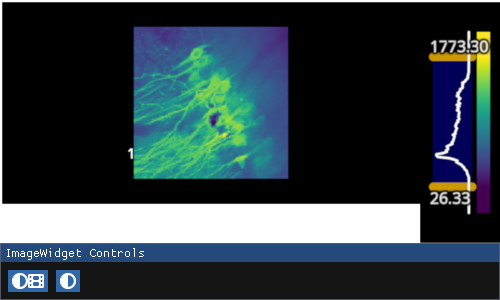

In [55]:
fpl.ImageWidget(Y.std(axis=-1), cmap="viridis").show()

In [56]:
Mod = [[np.maximum(ij[c] - 2 * gHalf[c], 0), np.minimum(ij[c] + 2 * gHalf[c] + 1, d[c])] for c in range(len(ij))]

In [57]:
ModLen = [m[1] - m[0] for m in Mod]
Lag = [ijSig[c] - Mod[c][0] for c in range(len(ij))]

In [58]:
ModLen

[np.int64(21), np.int64(21)]

In [59]:
Lag

[array([ 5, 16]), array([ 5, 16])]

In [60]:
Mod

[[np.int64(48), np.int64(69)], [np.int64(69), np.int64(90)]]

In [61]:
dataTemp = np.zeros(ModLen)
dataTemp[tuple([slice(*a) for a in Lag])] = coef

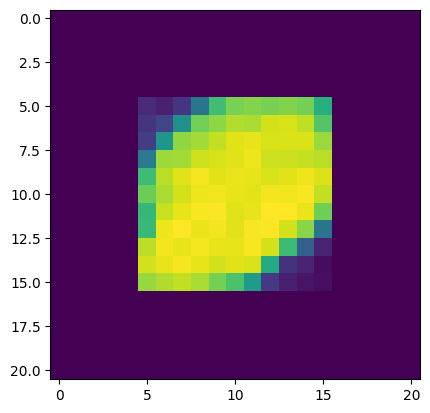

In [62]:
plt.imshow(dataTemp)

In [63]:
dataTemp = imblur(dataTemp[..., np.newaxis], sig=gSig, siz=gSiz, kernel=kernel)

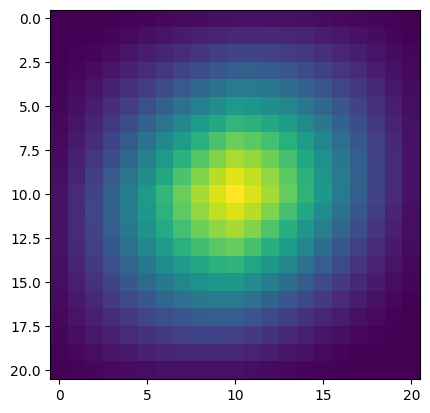

In [64]:
plt.imshow(dataTemp)

In [65]:
temp = dataTemp * score.reshape([1] * (Y.ndim - 1) + [-1])

In [66]:
temp.shape

(21, 21, 10000)

RFBOutputContext()

JupyterWgpuCanvas()
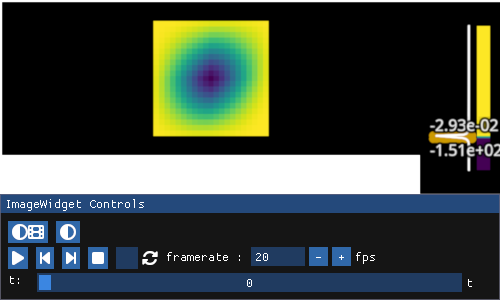

In [67]:
fpl.ImageWidget(temp.T, cmap="viridis").show()

In [68]:
rho[tuple([slice(*a) for a in Mod])] -= temp.copy()

In [69]:
rho.shape

(121, 123, 10000)

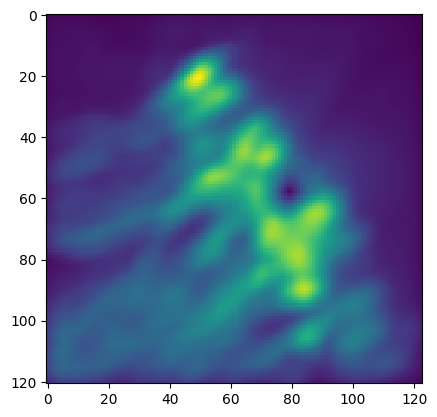

In [70]:
plt.imshow(rho.std(axis=-1))

In [71]:
v[tuple([slice(*a) for a in Mod])] = np.sum(rho[tuple([slice(*a) for a in Mod])] ** 2, axis=-1)

In [72]:
v.shape

(121, 123)

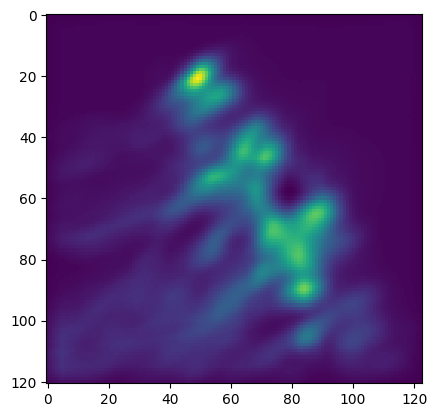

In [73]:
plt.imshow(v)

In [74]:
A, C, centers, b, f = greedyROI(Y, nr=100)

/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/decomposition/_nmf.py:1759: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


In [75]:
Y.shape

(121, 123, 10000)

In [76]:
from ipywidgets import HBox

In [77]:
import numba

@numba.guvectorize([(numba.float32[:], numba.float32[:])], "(n)->(n)")
def rolling_percentile(trace: np.ndarray, out: np.ndarray):
    for i in range(0, trace.size - 1):
        out[i] = np.percentile(trace[i:i + 30], 5)


@numba.njit(parallel=True)
def rolling_percentile_movie(m, output):
    t, row, col = m.shape
    for i in numba.prange(row):
        for j in range(col):
            rolling_percentile(m[:, i, j], output[:, i, j])

In [78]:
movie_filt = np.zeros(movie.shape, dtype=np.float32)
rolling_percentile_movie(movie, movie_filt)

In [79]:
imgs = [img.T for img in A.reshape(Y.shape[1], Y.shape[0], A.shape[-1]).T]

iw_movie = fpl.ImageWidget(movie_filt, cmap="viridis", figure_kwargs={"canvas": "glfw"})
iw_movie.figure.canvas.cursor = "crosshair"

fig_comps = fpl.Figure(canvas="glfw")

rows = 10
columns = 10

spacing = 10

cursor = fpl.Cursor(size=10, color="magenta", alpha=0.25)

index = 0
for i in range(rows):
    for j in range(columns):
        img = imgs[index]
        # offset is x, y, z position
        offset = (j * img.shape[1] + spacing * j, i * img.shape[0] + spacing * i, 0)
        img_graphic = fig_comps[0, 0].add_image(img, cmap="viridis", offset=offset)
        cursor.add(img_graphic)

        text_label = fig_comps[0, 0].add_text(
            str(index),
            face_color="r",
            font_size=15,
            outline_color="w",
            outline_thickness=0.05,
            anchor="bottom-right",
            offset=offset
        )

        index += 1

fig_comps.canvas.cursor = "crosshair"
fig_comps[0, 0].axes.visible = False

cursor.add(iw_movie.managed_graphics[0])

fig_comps.show(), iw_movie.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


(<wgpu.gui.glfw.GlfwWgpuCanvas at 0x7f20c9bd69d0>,
 <wgpu.gui.glfw.GlfwWgpuCanvas at 0x7f2178299ad0>)

In [80]:
iw_movie.window_funcs = {"t": (np.mean, 19)}